<a href="https://colab.research.google.com/github/sshafika-code/student-score-predictor/blob/main/Student_exam_score_predict.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 rows:
   study_hours  attendance  sleep_hours  exam_score
0     4.370861   82.101582     4.515619   50.606921
1     9.556429   54.206998     8.512765   72.849026
2     7.587945   58.081436     6.526262   64.618399
3     6.387926   94.927709     8.132287   67.440164
4     2.404168   80.321453     5.600248   41.749400

Summary statistics (mean, std, min, max):
       study_hours  attendance  sleep_hours  exam_score
count   200.000000  200.000000   200.000000  200.000000
mean      5.356056   75.218757     6.603364   58.953472
std       2.654023   14.650060     1.536544   14.651505
min       1.049699   50.253079     4.054188   22.898448
25%       3.057242   63.073125     5.277602   46.946849
50%       5.450376   77.081994     6.626997   59.557718
75%       7.811737   87.109966     8.055574   69.945733
max       9.881982   99.525257     8.998588   89.027449

Correlation with exam_score:
exam_score     1.000000
study_hours    0.885189
attendance     0.227403
sleep_hours    0.110934
N

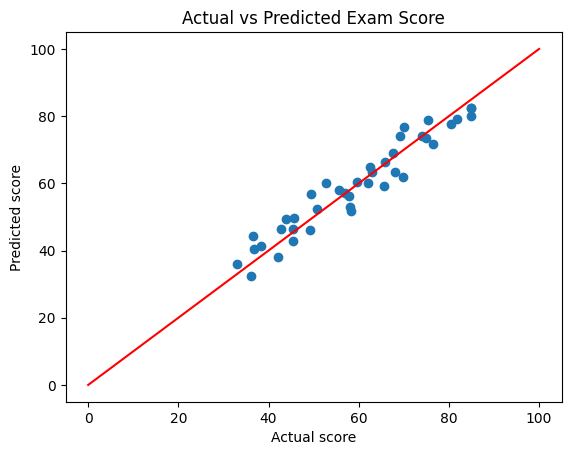


Predicted score: 67.0


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# STEP 1: Create a sample dataset (synthetic, for learning)
np.random.seed(42)
n = 200
study_hours = np.random.uniform(1, 10, n)
attendance = np.random.uniform(50, 100, n)
sleep_hours = np.random.uniform(4, 9, n)
noise = np.random.normal(0, 5, n)

# Score depends on the three features plus random noise
score = 5 * study_hours + 0.3 * attendance + 1.5 * sleep_hours + noise
score = np.clip(score, 0, 100)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "sleep_hours": sleep_hours,
    "exam_score": score,
})

# STEP 2: Statistics (understand the data)
print("First 5 rows:")
print(df.head())
print("\nSummary statistics (mean, std, min, max):")
print(df.describe())
print("\nCorrelation with exam_score:")
print(df.corr()["exam_score"].sort_values(ascending=False))

# STEP 3: Split data into training (80%) and testing (20%)
X = df[["study_hours", "attendance", "sleep_hours"]]
y = df["exam_score"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# STEP 4: Train the ML model
model = LinearRegression()
model.fit(X_train, y_train)

# STEP 5: Evaluate the model on unseen data
predictions = model.predict(X_test)
r2 = r2_score(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
print(f"\nR2 score: {r2:.3f}")
print(f"RMSE: {rmse:.2f} marks")

print("\nFeature coefficients:")
for name, coef in zip(X.columns, model.coef_):
    print(f"  {name}: {coef:.2f}")

# STEP 6: Chart - actual vs predicted
plt.scatter(y_test, predictions)
plt.plot([0, 100], [0, 100], color="red")
plt.xlabel("Actual score")
plt.ylabel("Predicted score")
plt.title("Actual vs Predicted Exam Score")
plt.savefig("actual_vs_predicted.png")
plt.show()

# STEP 7: Predict for a new student
new_student = pd.DataFrame(
    {"study_hours": [6], "attendance": [90], "sleep_hours": [7]}
)
print(f"\nPredicted score: {model.predict(new_student)[0]:.1f}")